<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/03_descriptive_pca_sahil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA on the numeric design attributes, by decade

Principal component analysis of the seven numeric design attributes in `data/bgg_clean.csv`: minimum and maximum players, minimum and maximum play time, minimum age, and the number of mechanics and categories listed. The components are then read back into the original attributes, and each decade's position on them is marked.

Scope: games published in the 1970s through the 2020s with all seven attributes known. PCA is run on numeric attributes only; the mechanic and category mix is covered by the chart notebook. Steps follow the course PCA lab: check spread, standardize, fit, read the variance table and scree plot, read the loadings as correlations, compare with the unscaled version.

In [1]:
# --- Sahil Dalal: PCA on the numeric design attributes, by decade ---
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14. Every code and markdown cell in this notebook was generated with Claude Code and reviewed, run and edited by Sahil Dalal.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 1. Load and scope

In [2]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Load the cleaned catalogue straight from the repository; the same line works in Colab and locally.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# The seven numeric design attributes. Rows with any of them missing are dropped, as in the course PCA lab; no train/test split is needed for a descriptive analysis.
attrs = ["minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
dec = games[games["decade"] >= 1970].dropna(subset=attrs).copy()
dec["decade"] = dec["decade"].astype(int).astype(str) + "s"
print("games 1970s to 2020s with all seven attributes known:", len(dec), "of", (games["decade"] >= 1970).sum())
dec["decade"].value_counts().sort_index().to_frame("games")

games 1970s to 2020s with all seven attributes known: 19116 of 20983


,games
decade,
1970s,725
1980s,1223
1990s,1868
2000s,4115
2010s,9604
2020s,1581


In [4]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Figures are saved into the repository's figures folder when the notebook runs inside the repository, otherwise next to the notebook.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 2. Transform and check the spread

In [5]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Player counts and play times have long right tails (a few games last thousands of minutes), so they enter on a log10 scale, as in the chart notebook.
X = dec[attrs].copy()
for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
    X[col] = np.log10(X[col])
X = X.rename(columns={col: "log10_" + col for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]})
X.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
log10_minplayers,19116.0,0.28,0.15,0.0,0.30,0.30,0.30,1.00
log10_maxplayers,19116.0,0.64,0.25,0.0,0.60,0.60,0.78,3.00
log10_minplaytime,19116.0,1.58,0.39,0.0,1.30,1.48,1.78,4.78
log10_maxplaytime,19116.0,1.69,0.40,0.0,1.48,1.65,1.95,4.78
minage,19116.0,10.29,2.76,1.0,8.00,10.00,12.00,25.00
n_mechanics,19116.0,2.98,2.22,0.0,1.00,3.00,4.00,20.00
n_categories,19116.0,2.65,1.39,0.0,2.00,2.00,3.00,14.00


In [6]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Spread of each attribute before scaling. Without scaling, the attribute with the largest spread would dominate the first component.
spread = X.agg(["min", "max", "mean", "std"]).T.sort_values("std", ascending=False)
print("ratio of largest to smallest standard deviation:", round(spread["std"].max() / spread["std"].min(), 1))
spread.round(2)

ratio of largest to smallest standard deviation: 18.7


,min,max,mean,std
minage,1.0,25.00,10.29,2.76
n_mechanics,0.0,20.00,2.98,2.22
n_categories,0.0,14.00,2.65,1.39
log10_maxplaytime,0.0,4.78,1.69,0.40
log10_minplaytime,0.0,4.78,1.58,0.39
log10_maxplayers,0.0,3.00,0.64,0.25
log10_minplayers,0.0,1.00,0.28,0.15


Minimum age has a standard deviation of 2.76 years against 0.15 for log player count, a ratio of about 19. Standardizing puts every attribute on the same footing before PCA.

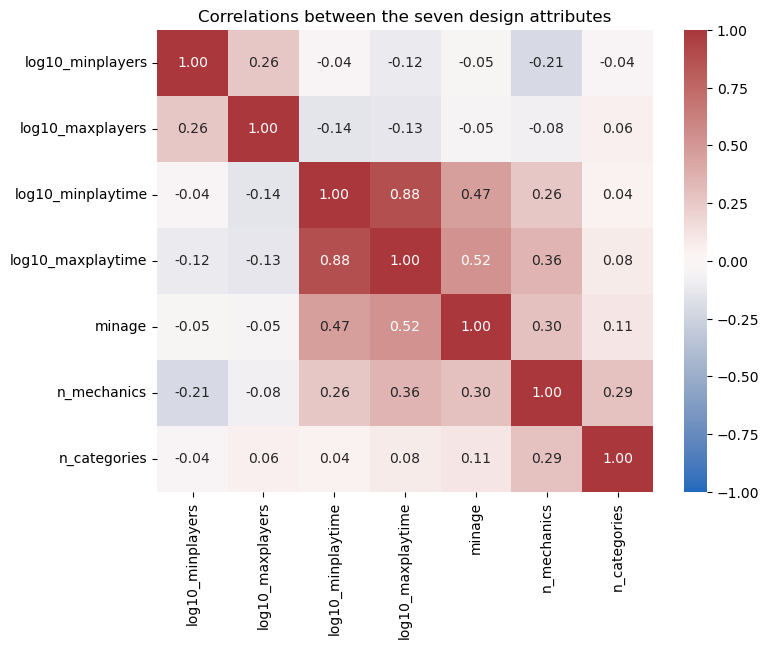

In [7]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Correlations between the seven attributes.
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag")
plt.title("Correlations between the seven design attributes")
save("03_attribute_correlations.png")

## 3. Standardize and fit

In [8]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Standardize to mean 0 and standard deviation 1, then fit PCA with all seven components.
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
pcs = PCA(n_components=7)
scores = pcs.fit_transform(scaled_df)
pc_names = ["PC" + str(i + 1) for i in range(pcs.n_components_)]
scores_df = pd.DataFrame(scores, columns=pc_names)
scaled_df.agg(["mean", "std"]).round(3)

,log10_minplayers,log10_maxplayers,log10_minplaytime,log10_maxplaytime,minage,n_mechanics,n_categories
mean,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [9]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Eigenvalue, share of variance, and cumulative share for each component.
summary_df = pd.DataFrame({
    "Eigenvalue": pcs.explained_variance_,
    "% of variance": pcs.explained_variance_ratio_ * 100,
    "Cumulative %": np.cumsum(pcs.explained_variance_ratio_) * 100,
}, index=pc_names)
summary_df.round(2)

,Eigenvalue,% of variance,Cumulative %
PC1,2.55,36.43,36.43
PC2,1.23,17.62,54.05
PC3,1.17,16.71,70.76
PC4,0.73,10.40,81.16
PC5,0.62,8.79,89.95
PC6,0.59,8.44,98.39
PC7,0.11,1.61,100.00


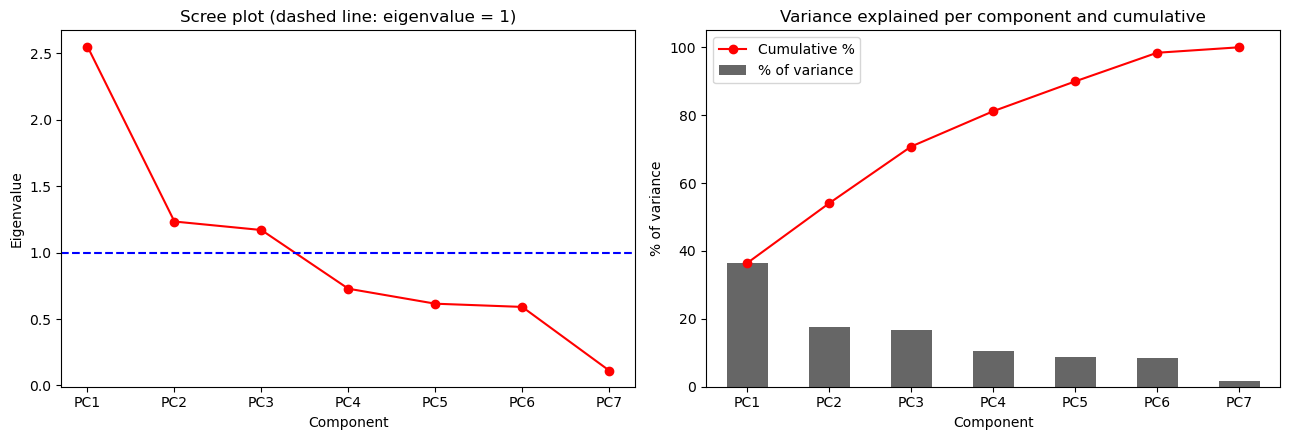

In [10]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Scree plot with the eigenvalue = 1 line, and the share of variance with its cumulative curve.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
summary_df["Eigenvalue"].plot(marker="o", color="red", ax=axes[0])
axes[0].axhline(y=1, color="b", linestyle="--")
axes[0].set_title("Scree plot (dashed line: eigenvalue = 1)")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Eigenvalue")
summary_df["% of variance"].plot.bar(color="0.4", ax=axes[1], rot=0)
summary_df["Cumulative %"].plot(marker="o", color="red", ax=axes[1])
axes[1].set_title("Variance explained per component and cumulative")
axes[1].set_xlabel("Component")
axes[1].set_ylabel("% of variance")
axes[1].legend(["Cumulative %", "% of variance"])
plt.tight_layout()
save("03_scree.png")

Three components have eigenvalues above 1 (2.55, 1.23, 1.17) and together carry 70.8% of the variance; two carry 54.1% and four carry 81.2%. The scree plot bends after the third component.

## 4. Read the components back into the attributes

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
log10_minplayers,-0.23,0.79,-0.04,-0.47,0.28,-0.15,0.02
log10_maxplayers,-0.24,0.67,0.37,0.57,-0.16,-0.03,-0.01
log10_minplaytime,0.86,0.22,-0.27,-0.06,-0.25,-0.17,-0.23
log10_maxplaytime,0.91,0.16,-0.18,0.02,-0.19,-0.14,0.24
minage,0.71,0.20,0.01,0.09,0.32,0.59,-0.02
n_mechanics,0.57,-0.22,0.49,0.14,0.46,-0.38,-0.02
n_categories,0.23,-0.03,0.83,-0.38,-0.31,0.15,-0.00


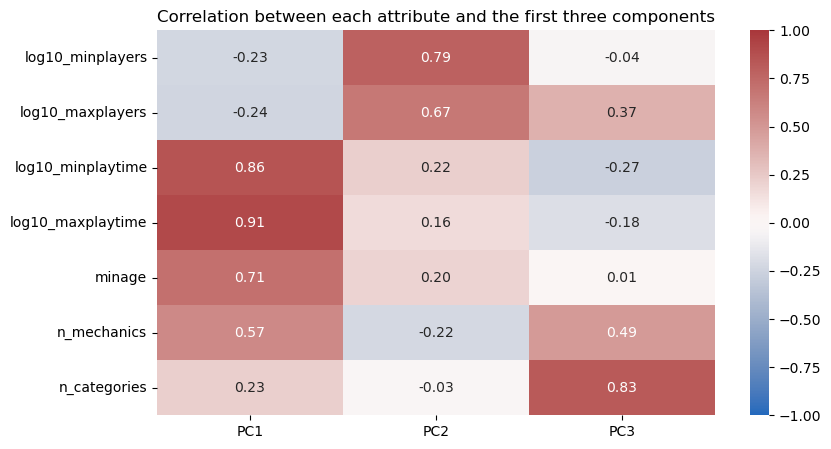

In [11]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Loadings as correlations between each attribute and each component (the component matrix, as in the course lab).
loadings_df = pd.concat([scores_df, scaled_df], axis=1).corr().loc[scaled_df.columns, pc_names]
plt.figure(figsize=(9, 5))
sns.heatmap(loadings_df[["PC1", "PC2", "PC3"]], annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag")
plt.title("Correlation between each attribute and the first three components")
save("03_loadings.png")
loadings_df.round(2)

PC1 correlates 0.91 with maximum play time, 0.86 with minimum play time, 0.71 with minimum age, and 0.57 with the number of mechanics; player counts sit at -0.23 and -0.24. PC2 correlates 0.79 with minimum players and 0.67 with maximum players, and below 0.25 in magnitude with everything else. PC3 correlates 0.83 with the number of categories and 0.49 with the number of mechanics.

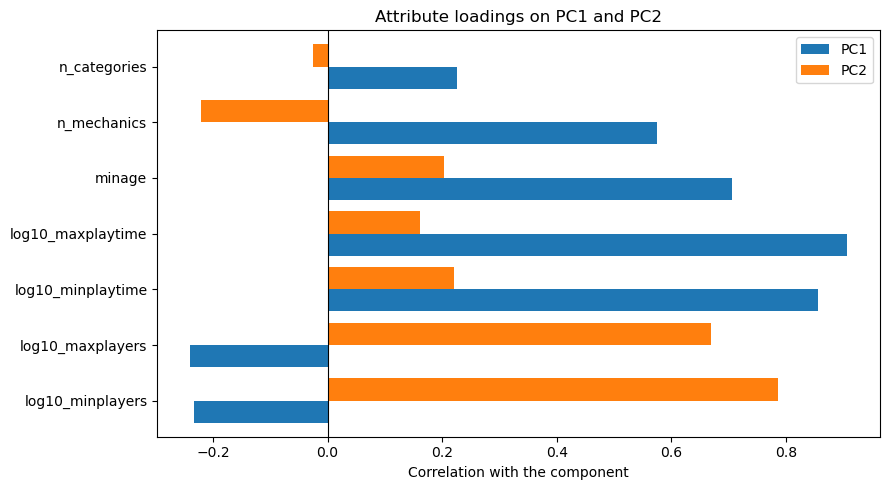

In [12]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# The same loadings as bars, for the first two components.
loadings_df[["PC1", "PC2"]].plot.barh(figsize=(9, 5), width=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with the component")
plt.title("Attribute loadings on PC1 and PC2")
plt.tight_layout()
save("03_loadings_bars.png")

## 5. The same analysis without scaling

In [13]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# PCA on the log-transformed but unscaled attributes, to show what scaling changes.
pcs_raw = PCA(n_components=7).fit(X)
raw_summary = pd.DataFrame({
    "% of variance": pcs_raw.explained_variance_ratio_ * 100,
    "Cumulative %": np.cumsum(pcs_raw.explained_variance_ratio_) * 100,
}, index=pc_names).round(1)
weights_raw = pd.DataFrame(pcs_raw.components_[:2].T, index=X.columns, columns=["PC1 weight", "PC2 weight"]).round(2)
display(raw_summary.head(3))
weights_raw

,% of variance,Cumulative %
PC1,58.7,58.7
PC2,28.0,86.6
PC3,11.3,97.9


,PC1 weight,PC2 weight
log10_minplayers,-0.01,-0.01
log10_maxplayers,-0.01,-0.00
log10_minplaytime,0.07,-0.01
log10_maxplaytime,0.08,0.00
minage,0.88,-0.47
n_mechanics,0.46,0.85
n_categories,0.12,0.25


Unscaled, the first component carries 58.7% of the variance and its weights are 0.88 on minimum age and 0.46 on the number of mechanics, with everything else below 0.13 in magnitude: the component follows the attribute with the largest spread rather than the pattern across attributes. The scaled version above is the one used from here on.

## 6. Where each decade sits on the first two components

,PC1,PC2
decade,,
1970s,1.03,-0.21
1980s,0.74,0.08
1990s,0.08,0.25
2000s,-0.35,0.16
2010s,-0.23,-0.04
2020s,0.38,-0.61


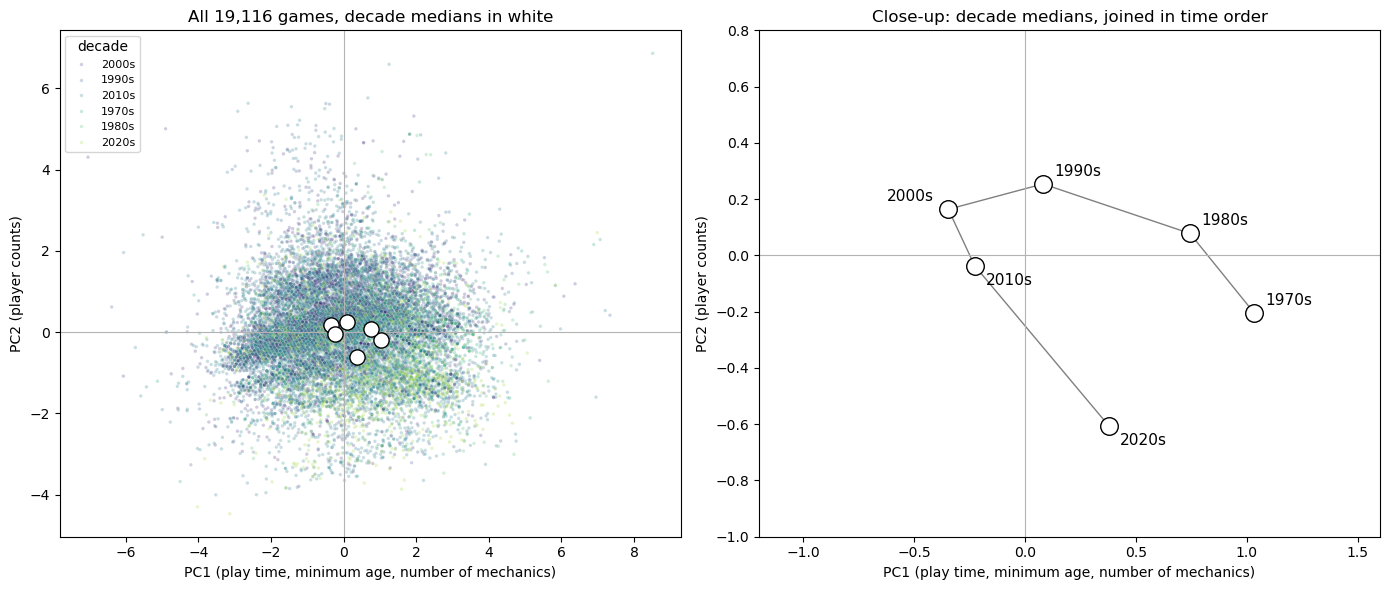

In [14]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Scores on PC1 and PC2 for every game (left), and a close-up of each decade's median position joined in time order (right).
plot_df = pd.concat([dec[["decade"]].reset_index(drop=True), scores_df[["PC1", "PC2"]]], axis=1)
centres = plot_df.groupby("decade")[["PC1", "PC2"]].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="decade", s=6, alpha=0.25, palette="viridis", ax=axes[0])
axes[0].scatter(centres["PC1"], centres["PC2"], s=120, c="white", edgecolor="black", zorder=3)
axes[0].axhline(0, color="0.7", linewidth=0.8)
axes[0].axvline(0, color="0.7", linewidth=0.8)
axes[0].set_title(f"All {len(plot_df):,} games, decade medians in white")
axes[0].set_xlabel("PC1 (play time, minimum age, number of mechanics)")
axes[0].set_ylabel("PC2 (player counts)")
axes[0].legend(fontsize=8, title="decade")
axes[1].plot(centres["PC1"], centres["PC2"], color="0.5", linewidth=1, zorder=2)
axes[1].scatter(centres["PC1"], centres["PC2"], s=160, c="white", edgecolor="black", zorder=3)
offsets = {"1970s": (8, 6), "1980s": (8, 6), "1990s": (8, 6), "2000s": (-44, 6), "2010s": (8, -14), "2020s": (8, -14)}
for label, row in centres.iterrows():
    axes[1].annotate(label, (row["PC1"], row["PC2"]), textcoords="offset points", xytext=offsets[label], fontsize=11)
axes[1].axhline(0, color="0.7", linewidth=0.8)
axes[1].axvline(0, color="0.7", linewidth=0.8)
axes[1].set_xlim(-1.2, 1.6)
axes[1].set_ylim(-1.0, 0.8)
axes[1].set_title("Close-up: decade medians, joined in time order")
axes[1].set_xlabel("PC1 (play time, minimum age, number of mechanics)")
axes[1].set_ylabel("PC2 (player counts)")
plt.tight_layout()
save("03_scores_by_decade.png")
centres.round(2)

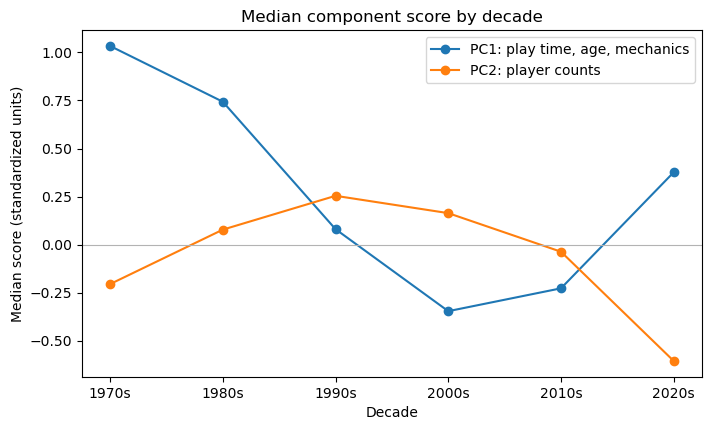

In [15]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Median position of each decade on PC1 and PC2, as lines.
ax = centres.plot(marker="o", figsize=(8, 4.5))
ax.axhline(0, color="0.7", linewidth=0.8)
ax.set_title("Median component score by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Median score (standardized units)")
ax.legend(["PC1: play time, age, mechanics", "PC2: player counts"])
save("03_decade_centres.png")

Median PC1 by decade: 1.03 (1970s), 0.74 (1980s), 0.08 (1990s), -0.35 (2000s), -0.23 (2010s), 0.38 (2020s). Median PC2: -0.21, 0.08, 0.25, 0.16, -0.04, -0.61. The 2020s is the only decade with a median PC2 below -0.3.

In [16]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# The same movement in the original attributes: median of each attribute by decade.
dec.groupby("decade")[attrs].median()

,minplayers,maxplayers,minplaytime,maxplaytime,minage,n_mechanics,n_categories
decade,,,,,,,
1970s,2.0,3.0,90.0,90.0,12.0,3.0,2.0
1980s,2.0,4.0,60.0,90.0,12.0,2.0,2.0
1990s,2.0,4.0,60.0,60.0,10.0,2.0,2.0
2000s,2.0,5.0,40.0,45.0,10.0,2.0,2.0
2010s,2.0,4.0,30.0,45.0,10.0,3.0,2.0
2020s,2.0,4.0,30.0,60.0,10.0,4.0,2.0


Median values by decade: maximum play time 90, 90, 60, 45, 45, 60 minutes; minimum play time 90, 60, 60, 40, 30, 30; minimum age 12, 12, 10, 10, 10, 10; mechanics listed 3, 2, 2, 2, 3, 4; maximum players 3, 4, 4, 5, 4, 4; minimum players 2 in every decade.

## 7. Notes on reading this notebook

- 19,116 of the 20,983 games published since 1970 have all seven attributes known; the rest are excluded here, not imputed.
- Components are linear combinations of standardized, log-transformed attributes; the sign of a component is arbitrary and is fixed by the software.
- The 2020s column covers 2020 to the January 2022 snapshot, 1,581 games against 9,604 for the 2010s in this subset.
- Figures are saved to `figures/` with the prefix `03_`.